In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
#from qitp.engine.unitary_approximation import UnitaryApproximation
#from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import cqite
#from qitp.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.hamiltonian import ScalableDiagHamiltonian

In [5]:
sizes = range(1,7)

In [6]:
hamiltonians = [ScalableDiagHamiltonian(n, gamma = 0.7) for n in sizes]

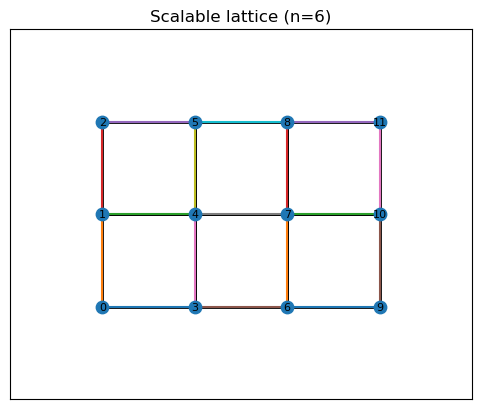

In [7]:
hamiltonians[5].draw()

In [8]:
depth=2
dt=1e-2
nsteps = 300
target = 0.4
trot = 2
degree = 2

In [9]:
results = {
    L: {
        "energy": [],
        "fidelity": [],
        "error": [],
        "magnetization": [],
    }
    for L in sizes
}

In [10]:
H_list = [SparsePauliOp.from_list(H.terms) for H in hamiltonians]

In [11]:
C_list = [[SparsePauliOp(term, coeff) for term, coeff in H.cterms] for H in hamiltonians]

In [12]:
backend = SimulatorBackend()

In [ ]:
results = cqite(
    H_list[1],
    C_list[1],
    target,
    degree,
    depth,
    trot,
    dt,
    nsteps,
    backend
)

In [14]:
energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
final_circuit = results["circuit"]
final_state = results["state"]

In [15]:
print(np.round(energies[-1],3))

-4.542


In [16]:
print(np.round(magnetizations[-1],3))

[0.296 0.296 0.219 0.219 0.296 0.296 1.   ]


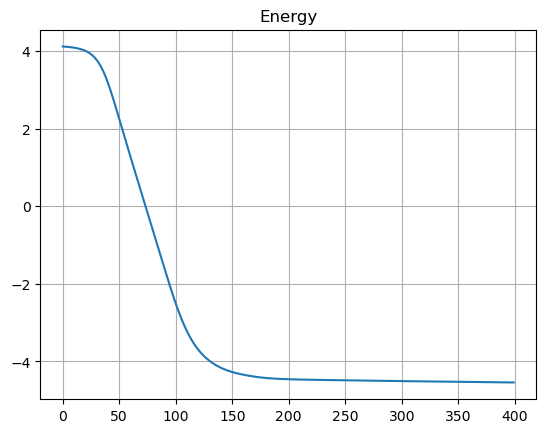

In [17]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

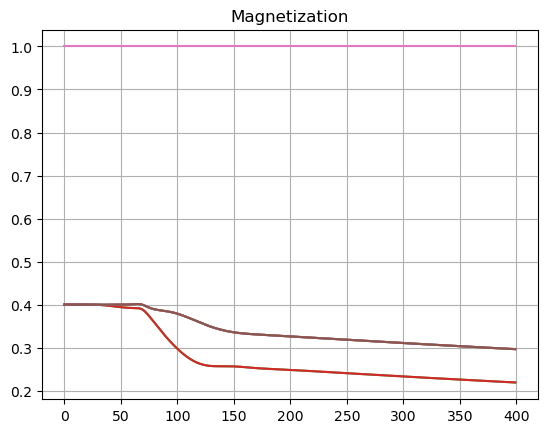

In [18]:
plt.plot(magnetizations); plt.title("Constraints"); plt.grid(); plt.show()

In [32]:
evals = np.linalg.eigvalsh(
    H_list[1].to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-4.9 -4.9 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1 -2.1
 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7 -0.7
 -0.7 -0.7 -0.7 -0.7  0.7  0.7  0.7  0.7  0.7  0.7  0.7  0.7  0.7  0.7
  0.7  0.7  0.7  0.7  0.7  0.7  0.7  0.7  2.1  2.1  2.1  2.1  2.1  2.1
  2.1  2.1  2.1  2.1  2.1  2.1  4.9  4.9]


In [38]:
Hm = H_list[1].to_matrix()

In [46]:
C = []

nqubits = H_list[1].num_qubits

for i in range(nqubits):

    p = ["I"] * nqubits
    p[i] = "Y"

    C.append(
        SparsePauliOp(
            ["".join(p)],
            coeffs=[1.0]
        ).to_matrix()
    )

I = np.eye(Hm.shape[0])

constraints_mat = [I]
constraints_mat.extend(C)

In [48]:
def compute_betas_dense(
    psi,
    Hm,
    constraints
):

    m = len(constraints)

    gamma = np.empty(m)
    Gmat = np.empty((m, m))

    #
    # H|psi>
    #
    Hpsi = Hm @ psi

    #
    # B_i|psi> (calcolati una sola volta)
    #
    Bpsi = [
        B @ psi
        for B in constraints
    ]

    #
    # Gamma e Gram
    #
    for i in range(m):

        Bipsi = Bpsi[i]

        gamma[i] = -np.real(
            np.vdot(
                Hpsi,
                Bipsi
            )
        )

        #
        # Triangolo superiore
        #
        for j in range(i, m):

            value = np.real(
                np.vdot(
                    Bipsi,
                    Bpsi[j]
                )
            )

            Gmat[i, j] = value
            Gmat[j, i] = value

    return np.linalg.pinv(Gmat) @ gamma

In [50]:
from scipy.sparse.linalg import expm_multiply

def cite_step(
    psi,
    Hm,
    constraints_mat,
    dt,
    nsub=100
):

    h = dt / nsub

    for _ in range(nsub):

        beta = compute_betas_dense(
            psi,
            Hm,
            constraints_mat
        )

        G = Hm.copy()

        for b, B in zip(beta, constraints_mat):
            G += b * B

        psi = expm_multiply(-h * G, psi)
        psi /= np.linalg.norm(psi)

    return psi

In [52]:
import numpy as np
from tqdm.notebook import tqdm

energies_exact = []
constraints_history = [[] for _ in C]

append_energy = energies_exact.append
append_constraints = [hist.append for hist in constraints_history]

psi_exact = psi.data

for step in tqdm(range(nsteps), desc="Exact CITE"):

    psi_exact = cite_step(
        psi_exact,
        Hm,
        constraints_mat,
        dt=dt
    )

    append_energy(
        np.real(
            np.vdot(
                psi_exact,
                Hm @ psi_exact
            )
        )
    )

    for append, B in zip(append_constraints, constraints_mat):

        append(
            np.real(
                np.vdot(
                    psi_exact,
                    B @ psi_exact
                )
            )
        )

NameError: name 'psi' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

energies = np.asarray(energies)
energies_exact = np.asarray(energies_exact)

iters = np.arange(len(energies))

fig, ax = plt.subplots(
    figsize=(8, 3.8),
    dpi=100
)

ax.plot(
    iters,
    energies_exact,
    lw=2.8,
    label="Exact CITE"
)

ax.plot(
    iters,
    energies,
    lw=2.5,
    ls="--",
    label="CQITE"
)

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel(r"$\langle H\rangle$", fontsize=12)

ax.grid(True, alpha=0.3)
ax.legend(frameon=False)

ax.tick_params(direction="in")

plt.tight_layout()
fig.savefig("zzxxy_exp.pdf", bbox_inches="tight", transparent=True)
plt.show()

In [ ]:
mag.shape

In [ ]:
mag = np.asarray(magnetizations)

fig, ax = plt.subplots(
    figsize=(8, 3.8)
)

eps = 5e-2

for k in range(mag.shape[1]):

    rel_error = np.abs((mag[:, k] - target) / target)

    ax.plot(
        rel_error * (1 + k * eps),
        lw=2,
        label=rf"$C_{k+1}$"
    )

ax.set_yscale("log")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Relative error")
ax.grid(alpha=.3)

ax.legend()

plt.tight_layout()

fig.savefig(
    "zzxxy_con.pdf",
    bbox_inches="tight",
    transparent=True
)

In [ ]:
mag = np.asarray(magnetizations)

fig, ax = plt.subplots(
    figsize=(8,3.8)
)

for k in range(mag.shape[1]):
    ax.plot(
        np.abs(mag[:,k]),
        lw=2,
        label=rf"$C_{k+1}$"
    )

#ax.set_yscale("log")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"$\langle C\rangle$")
ax.grid(alpha=.3)

ax.legend()

plt.tight_layout()

fig.savefig("zzxxy_mag.pdf", bbox_inches="tight", transparent=True)